# GD, SGD and Polyak stepsizes for logistic regression on the California housing data

Same data and preprocessing as `sgd_california.ipynb`, but now a **classification** problem: is a district
"expensive" (median house value above the median of the training set)? Labels $y_i \in \{-1, +1\}$, data points $x_i \in \mathbb{R}^9$.

$$f(w) = \frac{1}{n}\sum_{i=1}^n f_i(w), \qquad
f_i(w) = \log\bigl(1 + e^{-y_i\langle x_i, w\rangle}\bigr) + \frac{\lambda}{2}\|w\|^2 .$$

The $\ell_2$ term with a small $\lambda > 0$ makes $f$ strongly convex; without it $\mu = 0$ and the theorems do not apply.

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
from scipy.special import expit
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

## Setup
$80\%$ of the data is used for training (the functions $f_i$); the other $20\%$ is held out and not used.
Preprocessing as before (**log + clip**): logarithm of `AveRooms`, `AveBedrms`, `Population`, `AveOccup`;
standardize with the training statistics; clip to $[-3, 3]$; add the constant feature $1$ (bias).
Label: $y_i = +1$ if the median house value is above the training median, else $y_i = -1$ (so the classes are balanced).

In [2]:
TEST_SIZE = 0.2
SEED = 0          # SGD randomness
SPLIT_SEED = 2    # train/test partition
LOG_FEATURES = ["AveRooms", "AveBedrms", "Population", "AveOccup"]
CLIP = 3.0
LAM = 0.01        # l2 regularization lambda (= mu)

data = fetch_california_housing()
FEATURES = data.feature_names + ["bias"]
raw_train, raw_test, value_train, value_test = train_test_split(
    data.data, data.target, test_size=TEST_SIZE, random_state=SPLIT_SEED)


def make_features(raw_train, raw_test, log=True, clip=CLIP):
    # log of the skewed features, standardize with the train statistics, clip, add bias
    log_idx = [data.feature_names.index(name) for name in LOG_FEATURES]

    def transform(R):
        R = R.copy()
        if log:
            R[:, log_idx] = np.log(R[:, log_idx])
        return R

    T_train, T_test = transform(raw_train), transform(raw_test)
    mean, std = T_train.mean(axis=0), T_train.std(axis=0)
    out = []
    for T in (T_train, T_test):
        Z = (T - mean) / std
        if clip is not None:
            Z = np.clip(Z, -clip, clip)
        out.append(np.hstack([Z, np.ones((len(Z), 1))]))
    return out


X_train, X_test = make_features(raw_train, raw_test)
threshold = np.median(value_train)
y_train = np.where(value_train > threshold, 1.0, -1.0)
N, D = X_train.shape
print(f"n = {N} training points (held out: {len(X_test)}), d = {D}, "
      f"threshold = {threshold:.3f} (x $100,000), share of y = +1: {np.mean(y_train > 0):.3f}")

n = 16512 training points (held out: 4128), d = 9, threshold = 1.793 (x $100,000), share of y = +1: 0.500


## The functions
With $z_i = y_i\langle x_i, w\rangle$ and the sigmoid $\sigma(t) = \frac{1}{1+e^{-t}}$:
$$\nabla f_i(w) = -y_i\,\sigma(-z_i)\,x_i + \lambda w, \qquad
\nabla^2 f_i(w) = \sigma(z_i)\bigl(1-\sigma(z_i)\bigr)\,x_ix_i^\top + \lambda I .$$
`i` can be one index or an array of indices, and `w` one point of shape `(d,)` or a batch of shape `(..., d)`.

In [3]:
def f_i(X, y, i, w):
    # f_i(w) = log(1 + exp(-y_i <x_i, w>)) + lam/2 ||w||^2
    z = y[i] * np.einsum("...j,...j->...", X[i], w)
    return np.logaddexp(0, -z) + 0.5 * LAM * np.sum(w ** 2, axis=-1)


def grad_f_i(X, y, i, w):
    # grad f_i(w) = -y_i sigma(-z_i) x_i + lam w
    z = y[i] * np.einsum("...j,...j->...", X[i], w)
    return -(y[i] * expit(-z))[..., None] * X[i] + LAM * w


def f(X, y, w):
    # f(w) = 1/n sum_i log(1 + exp(-y_i <x_i, w>)) + lam/2 ||w||^2
    z = y * (w @ X.T)
    return np.mean(np.logaddexp(0, -z), axis=-1) + 0.5 * LAM * np.sum(w ** 2, axis=-1)


def grad_f(X, y, w):
    # grad f(w) = -1/n X^T (y * sigma(-z)) + lam w
    z = y * (w @ X.T)
    return -(y * expit(-z)) @ X / len(y) + LAM * w


def hess_f(X, y, w):
    # Hessian of f at one point w: 1/n X^T diag(sigma(z)(1 - sigma(z))) X + lam I
    s = expit(y * (X @ w))
    return (X * (s * (1 - s))[:, None]).T @ X / len(y) + LAM * np.eye(X.shape[1])

## Constants of the problem
* $\sigma(1-\sigma) \le \frac{1}{4}$, so $L_i = \frac{\|x_i\|^2}{4} + \lambda$, and $L = \lambda_{\max}\bigl(\frac{1}{4n}X^\top X\bigr) + \lambda$
  (attained at $w = 0$, where $\sigma = \frac{1}{2}$).
* $\sigma(1-\sigma) > 0$ but tends to $0$ far away, so the only global constant is $\mu = \lambda$.
* There is no closed form for $w^\star$. We compute it with **Newton's method** $w \leftarrow w - (\nabla^2 f(w))^{-1}\nabla f(w)$,
  which converges to machine precision in a few steps for $d = 9$. GD and SGD do not use it: $w^\star$ is only the
  reference for the error $\|w^k - w^\star\|^2$, and $f^\star = f(w^\star)$ is needed by the Polyak stepsize.
* $A = 2L_{\max}$, $C = 2\sigma_\star^2$, $\sigma_\star^2 = \frac{1}{n}\sum_i\|\nabla f_i(w^\star)\|^2$ (Exercise 29), as before.

In [4]:
def newton(X, y, iters=50, tol=1e-15):
    w = np.zeros(X.shape[1])
    for _ in range(iters):
        g = grad_f(X, y, w)
        if np.linalg.norm(g) < tol:
            break
        w = w - np.linalg.solve(hess_f(X, y, w), g)
    return w


def constants(X, y):
    n = len(y)
    w_star = newton(X, y)
    L_i = np.sum(X ** 2, axis=1) / 4 + LAM
    L = np.linalg.eigvalsh(X.T @ X / (4 * n))[-1] + LAM
    G = grad_f_i(X, y, np.arange(n), w_star)                # rows: grad f_i(w*)
    sigma2 = np.mean(np.sum(G ** 2, axis=1))                # sigma_*^2
    return dict(w_star=w_star, f_star=f(X, y, w_star), L_i=L_i, L_max=L_i.max(), L_bar=L_i.mean(),
                L=L, mu=LAM, A=2 * L_i.max(), C=2 * sigma2, sigma2=sigma2)


c = constants(X_train, y_train)
w_star, f_star, mu, L, A, C = c["w_star"], c["f_star"], c["mu"], c["L"], c["A"], c["C"]
eig_star = np.linalg.eigvalsh(hess_f(X_train, y_train, w_star))
print(f"mu = lambda = {mu:.4f}, L = {L:.4f}, L_bar = {c['L_bar']:.3f}, L_max = {c['L_max']:.3f}")
print(f"A = {A:.2f}, C = {C:.3f}, f* = {f_star:.4f}")
print(f"||grad f(w*)|| = {np.linalg.norm(grad_f(X_train, y_train, w_star)):.1e}  (Newton)")
print(f"eigenvalues of the Hessian at w*: [{eig_star[0]:.4f}, {eig_star[-1]:.4f}]  (global: mu = {mu}, L = {L:.4f})")
print("w* =", ", ".join(f"{name} {v:+.4f}" for name, v in zip(FEATURES, w_star)))
print(f"share of training points classified correctly by w*: {np.mean(np.sign(X_train @ w_star) == y_train):.3f}")

mu = lambda = 0.0100, L = 0.5186, L_bar = 1.982, L_max = 11.343
A = 22.69, C = 1.823, f* = 0.4234
||grad f(w*)|| = 7.3e-17  (Newton)
eigenvalues of the Hessian at w*: [0.0163, 0.3137]  (global: mu = 0.01, L = 0.5186)
w* = MedInc +2.0372, HouseAge +0.3427, AveRooms -0.3525, AveBedrms +0.2568, Population +0.1568, AveOccup -0.6910, Latitude -1.3416, Longitude -1.1712, bias +0.1224
share of training points classified correctly by w*: 0.841


## Methods
All methods start from $w^0 = 0$. We measure the error $\|w^k - w^\star\|^2$ (for SGD: its mean over independent runs).

* **GD**: $w^{k+1} = w^k - \gamma_k\nabla f(w^k)$, either with a constant $\gamma_k = \frac{1}{L}$, or with the
  **Polyak stepsize** $\gamma_k = \frac{2D_f(w^k, w^\star)}{\|\nabla f(w^k) - \nabla f(w^\star)\|^2}$.
  Since $\nabla f(w^\star) = 0$, we have $D_f(w^k, w^\star) = f(w^k) - f^\star$, so
  $\gamma_k = \frac{2(f(w^k) - f^\star)}{\|\nabla f(w^k)\|^2}$.
* **SGD**: $w^{k+1} = w^k - \gamma\frac{\nabla f_{i_k}(w^k)}{np_{i_k}}$, where $i_k = i$ with probability $p_i$, with a constant $\gamma$:
  * **SGD-US** (uniform sampling): $p_i = \frac{1}{n}$, so the step is $\gamma\nabla f_{i_k}(w^k)$; $A = 2L_{\max}$;
  * **SGD-IS** (importance sampling): $p_i = \frac{L_i}{\sum_j L_j}$; then $A'' = \max_i\frac{L_i}{np_i} = \bar L$, so $A_{\rm IS} = 2\bar L$.

**Step count and time.** For every method we run single trajectories from $w^0 = 0$ and record the number of
steps, the number of gradient evaluations $\nabla f_i$ (one GD step costs $n$, one SGD step costs $1$) and the
wall-clock time until $\|w^k - w^\star\|^2 \le 10^{-2}\|w^0 - w^\star\|^2$.

Only the update steps are timed (checking the criterion is not). SGD numbers are means over $5$ seeds.
Each experiment prints its own results, and all of them are collected in the table at the end.

In [5]:
W0 = np.zeros(D)
RUNS = 200        # independent SGD runs used to estimate E||w^k - w*||^2
TOL = 1e-2        # the one target for all methods: ||w^k - w*||^2 <= TOL ||w^0 - w*||^2
R0 = np.sum((W0 - w_star) ** 2)
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)


def gd(stepsize, max_iters=5000, w0=W0, tol=TOL):
    # GD; stepsize(w, grad) -> gamma_k. Returns dict of per-iteration histories.
    w = w0.copy()
    hist = dict(err=[np.sum((w - w_star) ** 2)], gamma=[])
    t = 0.0
    for k in range(max_iters):
        t0 = time.perf_counter()
        g = grad_f(X_train, y_train, w)
        gamma = stepsize(w, g)
        w = w - gamma * g
        t += time.perf_counter() - t0
        hist.setdefault("time", []).append(t)
        hist["gamma"].append(gamma)
        hist["err"].append(np.sum((w - w_star) ** 2))
        if hist["err"][-1] <= tol * R0:
            break
    return {key: np.array(v) for key, v in hist.items()}


def gd_constant(gamma):
    return lambda w, g: gamma


def gd_polyak(w, g):
    # gamma_k = 2 (f(w^k) - f*) / ||grad f(w^k)||^2
    return 2 * (f(X_train, y_train, w) - f_star) / np.sum(g ** 2)


def sgd(stepsize, iters, runs=RUNS, w0=W0, seed=SEED, p=None):
    # `runs` independent copies of SGD; stepsize(i, w, g) -> gamma_k (one per run).
    # p = None: uniform sampling (SGD-US); otherwise i ~ p and g = grad f_i / (n p_i) (e.g. SGD-IS).
    # Returns E||w^k - w*||^2 for k = 0..iters.
    rng = np.random.default_rng(seed + 1)
    cp = None if p is None else np.cumsum(p)
    w = np.tile(w0, (runs, 1))
    err = np.empty(iters + 1)
    err[0] = np.mean(np.sum((w - w_star) ** 2, axis=1))
    with np.errstate(over="ignore", invalid="ignore"):       # large stepsizes may diverge
        for k in range(iters):
            if p is None:
                i = rng.integers(0, N, size=runs)
                g = grad_f_i(X_train, y_train, i, w)
            else:
                i = np.minimum(np.searchsorted(cp, rng.random(runs)), N - 1)
                g = grad_f_i(X_train, y_train, i, w) / (N * p[i])[:, None]
            w = w - stepsize(i, w, g)[:, None] * g
            err[k + 1] = np.mean(np.sum((w - w_star) ** 2, axis=1))
    return dict(err=err, w=w)


def sgd_constant(gamma):
    return lambda i, w, g: np.full(len(i), gamma)


# --- step count and time -------------------------------------------------------
SEEDS = 5
RESULTS = {}      # name -> (steps, grads, seconds), or None if not reached


def gd_step(stepsize):
    def step(w, rng):
        g = grad_f(X_train, y_train, w)
        return w - stepsize(w, g) * g
    return step


def sgd_step(gamma, p=None):
    cp = None if p is None else np.cumsum(p)

    def step(w, rng):
        if p is None:
            i = rng.integers(0, N)
            return w - gamma * grad_f_i(X_train, y_train, i, w)
        i = min(np.searchsorted(cp, rng.random()), N - 1)
        return w - gamma / (N * p[i]) * grad_f_i(X_train, y_train, i, w)
    return step


def measure(name, step, stochastic, max_steps, verbose=True):
    # Single trajectories from W0; only step() is timed. Mean over SEEDS seeds for SGD.
    seeds = SEEDS if stochastic else 1
    hits = []
    for s in range(seeds):
        rng = np.random.default_rng(SEED + 100 + s)
        w, t, hit = W0.copy(), 0.0, None
        for k in range(1, max_steps + 1):
            t0 = time.perf_counter()
            w = step(w, rng)
            t += time.perf_counter() - t0
            if np.sum((w - w_star) ** 2) <= TOL * R0:
                hit = (k, t)
                break
        hits.append(hit)
    cost = 1 if stochastic else N
    if all(h is not None for h in hits):            # reached in every seed
        steps, secs = np.mean([h[0] for h in hits]), np.mean([h[1] for h in hits])
        res = (steps, steps * cost, secs)
    else:
        res = None
    RESULTS[name] = res
    if verbose:
        print(f"  {name:18s}  {fmt(res)}")


def fmt(r):
    if r is None:
        return f"{'not reached':^43s}"
    steps, grads, secs = r
    return f"{steps:8.0f} steps, {grads:9.0f} grads, {1e3 * secs:7.1f} ms"


def save(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), dpi=150)
    plt.show()


TARGET = f"||w^k - w*||^2 <= {TOL:g} ||w^0 - w*||^2"
print(f"Target for all methods: {TARGET}")

Target for all methods: ||w^k - w*||^2 <= 0.01 ||w^0 - w*||^2


## Experiment 1: GD with a constant stepsize
$\gamma = \frac{1}{L}$; bound (Theorem 15): $\|w^k - w^\star\|^2 \le \bigl(1 - \frac{\mu}{L}\bigr)^k\|w^0 - w^\star\|^2$.

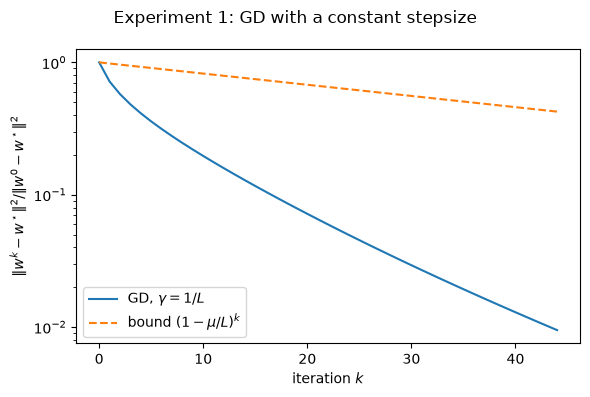

Target: ||w^k - w*||^2 <= 0.01 ||w^0 - w*||^2
GD 1/L: 44 steps (theory: 239 steps); bound violated: False
Step count and time until ||w^k - w*||^2 <= 0.01 ||w^0 - w*||^2:
  GD, 1/L                   44 steps,    726528 grads,    11.7 ms


In [6]:
gd_const = gd(gd_constant(1 / L))
k = np.arange(len(gd_const["err"]))

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(k, gd_const["err"] / R0, label=r"GD, $\gamma = 1/L$")
ax.semilogy(k, (1 - mu / L) ** k, "--", label=r"bound $(1-\mu/L)^k$")
ax.set_xlabel("iteration $k$")
ax.set_ylabel(r"$\|w^k-w^\star\|^2 / \|w^0-w^\star\|^2$")
ax.legend()
fig.suptitle("Experiment 1: GD with a constant stepsize")
save(fig, "log_exp1_gd.png")

print(f"Target: {TARGET}")
print(f"GD 1/L: {len(k) - 1} steps (theory: {np.log(1 / TOL) / (mu / L):.0f} steps); "
      f"bound violated: {np.any(gd_const['err'] / R0 > (1 - mu / L) ** k * (1 + 1e-9))}")
print(f"Step count and time until {TARGET}:")
measure("GD, 1/L", gd_step(gd_constant(1 / L)), stochastic=False, max_steps=5000)

## Experiment 2: GD with the Polyak stepsize
Checks: $\frac{1}{L} \le \gamma_k \le \frac{1}{\mu}$, and $\|w^{k+1} - w^\star\|^2 \le (1-\gamma_k\mu)\|w^k - w^\star\|^2$ at every step.
Dashed: the bounds $(1-\frac{\mu}{L})^k\|w^0 - w^\star\|^2$ (GD, $\gamma = \frac{1}{L}$) and $\prod_{j<k}(1-\gamma_j\mu)\,\|w^0 - w^\star\|^2$ (Polyak).

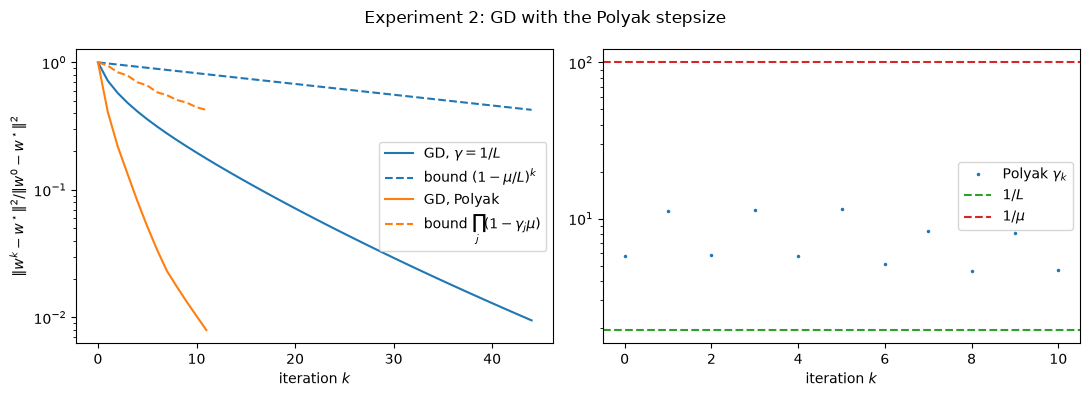

Target: ||w^k - w*||^2 <= 0.01 ||w^0 - w*||^2
GD Polyak: 11 steps (GD 1/L: 44 steps)
gamma_k in [4.6402, 11.4917], 1/L = 1.9283, 1/mu = 100.0000; 1/L <= gamma_k <= 1/mu for all k: True
one-step bound holds for all k: True
Step count and time until ||w^k - w*||^2 <= 0.01 ||w^0 - w*||^2:
  GD, Polyak                11 steps,    181632 grads,     8.9 ms


In [7]:
gd_pol = gd(gd_polyak)
kp = np.arange(len(gd_pol["err"]))
gam = gd_pol["gamma"]
bound_pol = np.concatenate([[1.0], np.cumprod(1 - gam * mu)])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.semilogy(k, gd_const["err"] / R0, color="C0", label=r"GD, $\gamma = 1/L$")
ax.semilogy(k, (1 - mu / L) ** k, "--", color="C0", label=r"bound $(1-\mu/L)^k$")
ax.semilogy(kp, gd_pol["err"] / R0, color="C1", label="GD, Polyak")
ax.semilogy(kp, bound_pol, "--", color="C1", label=r"bound $\prod_j(1-\gamma_j\mu)$")
ax.set_xlabel("iteration $k$")
ax.set_ylabel(r"$\|w^k-w^\star\|^2 / \|w^0-w^\star\|^2$")
ax.legend()
ax = axes[1]
ax.plot(gam, ".", ms=3, label=r"Polyak $\gamma_k$")
ax.axhline(1 / L, ls="--", color="C2", label=r"$1/L$")
ax.axhline(1 / mu, ls="--", color="C3", label=r"$1/\mu$")
ax.set_yscale("log")
ax.set_xlabel("iteration $k$")
ax.legend()
fig.suptitle("Experiment 2: GD with the Polyak stepsize")
save(fig, "log_exp2_polyak.png")

step_ok = gd_pol["err"][1:] <= (1 - gam * mu) * gd_pol["err"][:-1] * (1 + 1e-9)
print(f"Target: {TARGET}")
print(f"GD Polyak: {len(kp) - 1} steps (GD 1/L: {len(k) - 1} steps)")
print(f"gamma_k in [{gam.min():.4f}, {gam.max():.4f}], 1/L = {1 / L:.4f}, 1/mu = {1 / mu:.4f}; "
      f"1/L <= gamma_k <= 1/mu for all k: {np.all((gam >= 1 / L * (1 - 1e-9)) & (gam <= 1 / mu * (1 + 1e-9)))}")
print(f"one-step bound holds for all k: {np.all(step_ok)}")
print(f"Step count and time until {TARGET}:")
measure("GD, Polyak", gd_step(gd_polyak), stochastic=False, max_steps=5000)

## Experiment 3: SGD with the AC constants
Theorem 33 with $A = 2L_{\max}$, $C = 2\sigma_\star^2$ (Exercise 29): for $0 < \gamma \le \frac{1}{A}$,
$\ \mathbb{E}\|w^k - w^\star\|^2 \le (1-\gamma\mu)^k\|w^0 - w^\star\|^2 + \frac{\gamma C}{\mu}$.

**3a.** $\gamma = \frac{1}{A}$ and the bound. **3b.** $\gamma = \frac{1}{mA}$, $m = 1, 2, 4$: the neighbourhood
is proportional to $\gamma$. **3c.** $\gamma = \frac{m}{A}$, $m = 1, 2, 4, 8, 16$: stepsizes larger than the theory allows.

3a: gamma = 1/A = 0.0441: plateau 0.1506, radius gamma C / mu = 8.0375, bound violated: False
3b: gamma = 1/(1A): plateau 0.1506, radius 8.0375, plateau * m = 0.1506, bound violated: False


3b: gamma = 1/(2A): plateau 0.0728, radius 4.0187, plateau * m = 0.1456, bound violated: False


3b: gamma = 1/(4A): plateau 0.0357, radius 2.0094, plateau * m = 0.1427, bound violated: False
3c: gamma = 1/A = 0.0441: plateau 0.1506, reaches 1.1 x plateau after 2644 steps


3c: gamma = 2/A = 0.0882: plateau 0.3227, reaches 1.1 x plateau after 1039 steps


3c: gamma = 4/A = 0.1763: plateau 0.7433, reaches 1.1 x plateau after 368 steps


3c: gamma = 8/A = 0.3527: plateau 1.9799, reaches 1.1 x plateau after 111 steps


3c: gamma = 16/A = 0.7053: plateau 6.6610, reaches 1.1 x plateau after 12 steps


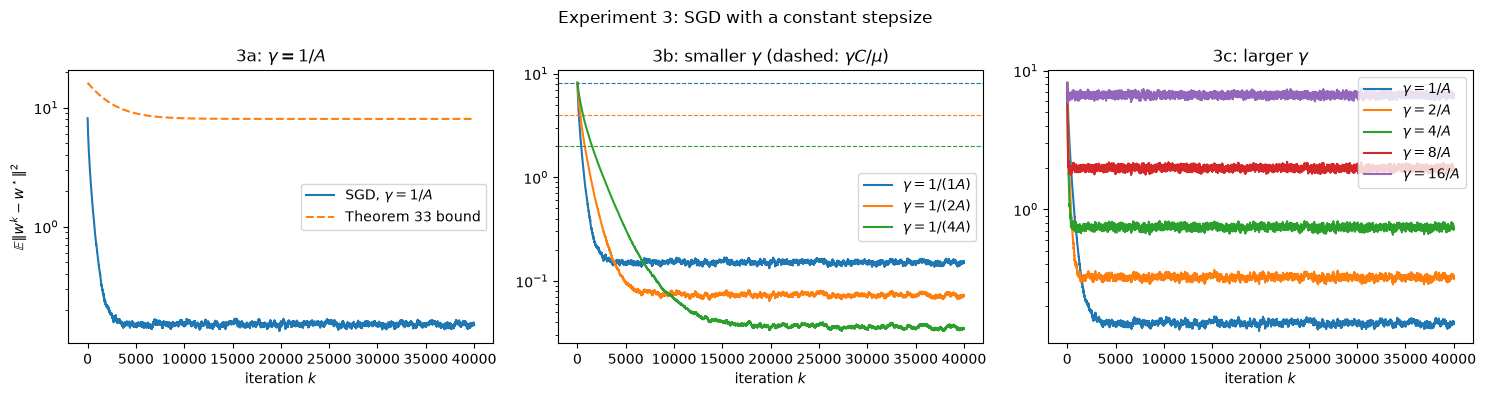

Step count and time until ||w^k - w*||^2 <= 0.01 ||w^0 - w*||^2 (single runs, mean over seeds; at most 60000 steps):


  SGD-US, 1/(4A)          8379 steps,      8379 grads,    84.9 ms


  SGD-US, 1/(2A)          4421 steps,      4421 grads,    44.4 ms
  SGD-US, 1/A             2680 steps,      2680 grads,    26.8 ms


  SGD-US, 2/A             2436 steps,      2436 grads,    24.4 ms


  SGD-US, 4/A            12331 steps,     12331 grads,   123.3 ms


In [8]:
ITERS = 40000
k3 = np.arange(ITERS + 1)

def bound33(gamma, k):
    return (1 - gamma * mu) ** k * R0 + gamma * C / mu

sgd_runs = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
# 3a
gamma = 1 / A
run = sgd_runs[1.0] = sgd(sgd_constant(gamma), ITERS)
ax = axes[0]
ax.semilogy(run["err"], label=r"SGD, $\gamma = 1/A$")
ax.semilogy(bound33(gamma, k3), "--", label="Theorem 33 bound")
ax.set_title(r"3a: $\gamma = 1/A$")
print(f"3a: gamma = 1/A = {gamma:.4f}: plateau {run['err'][-5000:].mean():.4f}, "
      f"radius gamma C / mu = {gamma * C / mu:.4f}, bound violated: {np.any(run['err'] > bound33(gamma, k3))}")
# 3b
ax = axes[1]
for m in [1, 2, 4]:
    gamma = 1 / (m * A)
    run = sgd_runs[1 / m] = sgd_runs.get(1 / m) or sgd(sgd_constant(gamma), ITERS)
    line, = ax.semilogy(run["err"], label=fr"$\gamma = 1/({m}A)$")
    ax.axhline(gamma * C / mu, ls="--", color=line.get_color(), lw=0.8)
    plateau = run["err"][-5000:].mean()
    print(f"3b: gamma = 1/({m}A): plateau {plateau:.4f}, radius {gamma * C / mu:.4f}, "
          f"plateau * m = {plateau * m:.4f}, bound violated: {np.any(run['err'] > bound33(gamma, k3))}")
ax.set_title(r"3b: smaller $\gamma$ (dashed: $\gamma C/\mu$)")
# 3c
ax = axes[2]
for m in [1, 2, 4, 8, 16]:
    gamma = m / A
    run = sgd_runs[m] = sgd_runs.get(m) or sgd(sgd_constant(gamma), ITERS)
    err = run["err"]
    ax.semilogy(np.where(np.isfinite(err), err, np.nan), label=fr"$\gamma = {m}/A$")
    plateau = err[-5000:].mean()
    if np.isfinite(plateau) and plateau < R0:
        hit = np.argmax(err <= 1.1 * plateau)
        print(f"3c: gamma = {m}/A = {gamma:.4f}: plateau {plateau:.4f}, "
              f"reaches 1.1 x plateau after {hit} steps")
    elif not np.isfinite(plateau):
        print(f"3c: gamma = {m}/A = {gamma:.4f}: diverges")
    else:
        print(f"3c: gamma = {m}/A = {gamma:.4f}: stable, but settles above the starting error "
              f"(plateau {plateau:.3g} > ||w^0 - w*||^2 = {R0:.3g})")
ax.set_title(r"3c: larger $\gamma$")
for ax in axes:
    ax.set_xlabel("iteration $k$")
    ax.legend()
axes[0].set_ylabel(r"$\mathbb{E}\|w^k-w^\star\|^2$")
fig.suptitle("Experiment 3: SGD with a constant stepsize")
save(fig, "log_exp3_sgd.png")

print(f"Step count and time until {TARGET} (single runs, mean over seeds; at most 60000 steps):")
for label, gamma in [("1/(4A)", 1 / (4 * A)), ("1/(2A)", 1 / (2 * A)), ("1/A", 1 / A),
                     ("2/A", 2 / A), ("4/A", 4 / A)]:
    measure(f"SGD-US, {label}", sgd_step(gamma), stochastic=True, max_steps=60000)

## Experiment 4: SGD with importance sampling (SGD-IS)
$p_i = \frac{L_i}{\sum_j L_j}$ and the step $\gamma\frac{\nabla f_i(w^k)}{np_i}$. Theorem 38: with $A'' = \max_i\frac{L_i}{np_i} = \bar L$,
$A_{\rm IS} = 2A'' = 2\bar L$, $\sigma_{\star,{\rm IS}}^2 = \frac{1}{n^2}\sum_i\frac{\|\nabla f_i(w^\star)\|^2}{p_i}$ and $C_{\rm IS} = 2\sigma_{\star,{\rm IS}}^2$,
for $0 < \gamma \le \frac{1}{A_{\rm IS}}$:
$\ \mathbb{E}\|w^k - w^\star\|^2 \le (1-\gamma\mu)^k\|w^0 - w^\star\|^2 + \frac{\gamma C_{\rm IS}}{\mu}$.

**4a.** $\gamma = \frac{1}{A_{\rm IS}}$ and the bound. **4b.** $\gamma = \frac{1}{mA_{\rm IS}}$, $m = 1, 2, 4$: the neighbourhood
is proportional to $\gamma$. **4c.** $\gamma = \frac{m}{A_{\rm IS}}$, $m = 1, 2, 3, 4$: stepsizes larger than the theory allows.
With IS the curvature of every step along $x_i$ is at most $\gamma\frac{L_i}{np_i} = \gamma\bar L$ (equal when $\sigma = \frac{1}{2}$), so all steps can overshoot at once when $\gamma\bar L > 2$, i.e. $m > 4$.

SGD-US: A    = 2 L_max =  22.69, gamma = 1/A    = 0.0441, C    = 1.823, radius gamma C / mu = 8.037
SGD-IS: A_IS = 2 L_bar =   3.96, gamma = 1/A_IS = 0.2523, C_IS = 1.869, radius gamma C / mu = 47.158


4a: gamma = 1/A_IS = 0.2523: plateau 1.1735, radius gamma C_IS / mu = 47.1576, bound violated: False
4b: gamma = 1/(1A_IS): plateau 1.1735, radius 47.1576, plateau * m = 1.1735, bound violated: False


4b: gamma = 1/(2A_IS): plateau 0.4851, radius 23.5788, plateau * m = 0.9702, bound violated: False


4b: gamma = 1/(4A_IS): plateau 0.2204, radius 11.7894, plateau * m = 0.8818, bound violated: False
4c: gamma = 1/A_IS = 0.2523: plateau 1.1735, reaches 1.1 x plateau after 235 steps


4c: gamma = 2/A_IS = 0.5046: plateau 3.4215, reaches 1.1 x plateau after 46 steps


4c: gamma = 3/A_IS = 0.7569: plateau 7.2317, reaches 1.1 x plateau after 5 steps


4c: gamma = 4/A_IS = 1.0093: stable, but settles above the starting error (plateau 12.8 > ||w^0 - w*||^2 = 8.15)


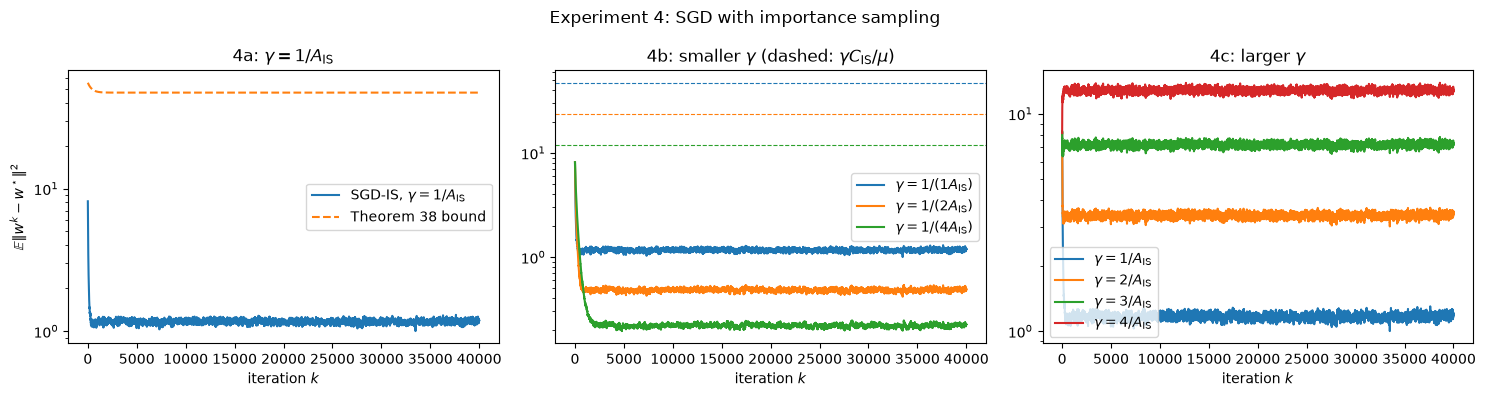

In [9]:
# importance sampling: p_i = L_i / sum_j L_j
p_is = c["L_i"] / c["L_i"].sum()
A_IS = 2 * np.max(c["L_i"] / (N * p_is))                                 # 2 A'' = 2 L_bar
G_star = grad_f_i(X_train, y_train, np.arange(N), w_star)               # rows: grad f_i(w*)
sigma2_is = np.sum(np.sum(G_star ** 2, axis=1) / p_is) / N ** 2         # (grad f(w*) = 0)
C_IS = 2 * sigma2_is
print(f"SGD-US: A    = 2 L_max = {A:6.2f}, gamma = 1/A    = {1 / A:.4f}, C    = {C:.3f}, "
      f"radius gamma C / mu = {C / (A * mu):.3f}")
print(f"SGD-IS: A_IS = 2 L_bar = {A_IS:6.2f}, gamma = 1/A_IS = {1 / A_IS:.4f}, C_IS = {C_IS:.3f}, "
      f"radius gamma C / mu = {C_IS / (A_IS * mu):.3f}")


def bound38(gamma, k):
    return (1 - gamma * mu) ** k * R0 + gamma * C_IS / mu


is_runs = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
# 4a
gamma = 1 / A_IS
run = is_runs[1.0] = sgd(sgd_constant(gamma), ITERS, p=p_is)
ax = axes[0]
ax.semilogy(run["err"], label=r"SGD-IS, $\gamma = 1/A_{\rm IS}$")
ax.semilogy(bound38(gamma, k3), "--", label="Theorem 38 bound")
ax.set_title(r"4a: $\gamma = 1/A_{\rm IS}$")
print(f"4a: gamma = 1/A_IS = {gamma:.4f}: plateau {run['err'][-5000:].mean():.4f}, "
      f"radius gamma C_IS / mu = {gamma * C_IS / mu:.4f}, bound violated: {np.any(run['err'] > bound38(gamma, k3))}")
# 4b
ax = axes[1]
for m in [1, 2, 4]:
    gamma = 1 / (m * A_IS)
    run = is_runs[1 / m] = is_runs.get(1 / m) or sgd(sgd_constant(gamma), ITERS, p=p_is)
    line, = ax.semilogy(run["err"], label=fr"$\gamma = 1/({m}A_{{\rm IS}})$")
    ax.axhline(gamma * C_IS / mu, ls="--", color=line.get_color(), lw=0.8)
    plateau = run["err"][-5000:].mean()
    print(f"4b: gamma = 1/({m}A_IS): plateau {plateau:.4f}, radius {gamma * C_IS / mu:.4f}, "
          f"plateau * m = {plateau * m:.4f}, bound violated: {np.any(run['err'] > bound38(gamma, k3))}")
ax.set_title(r"4b: smaller $\gamma$ (dashed: $\gamma C_{\rm IS}/\mu$)")
# 4c
ax = axes[2]
for m in [1, 2, 3, 4]:
    gamma = m / A_IS
    run = is_runs[m] = is_runs.get(m) or sgd(sgd_constant(gamma), ITERS, p=p_is)
    err = run["err"]
    ax.semilogy(np.where(np.isfinite(err), err, np.nan), label=fr"$\gamma = {m}/A_{{\rm IS}}$")
    plateau = err[-5000:].mean()
    if np.isfinite(plateau) and plateau < R0:
        hit = np.argmax(err <= 1.1 * plateau)
        print(f"4c: gamma = {m}/A_IS = {gamma:.4f}: plateau {plateau:.4f}, "
              f"reaches 1.1 x plateau after {hit} steps")
    elif not np.isfinite(plateau):
        print(f"4c: gamma = {m}/A_IS = {gamma:.4f}: diverges")
    else:
        print(f"4c: gamma = {m}/A_IS = {gamma:.4f}: stable, but settles above the starting error "
              f"(plateau {plateau:.3g} > ||w^0 - w*||^2 = {R0:.3g})")
ax.set_title(r"4c: larger $\gamma$")
for ax in axes:
    ax.set_xlabel("iteration $k$")
    ax.legend()
axes[0].set_ylabel(r"$\mathbb{E}\|w^k-w^\star\|^2$")
fig.suptitle("Experiment 4: SGD with importance sampling")
save(fig, "log_exp4_sgd_is.png")



## Experiment 5: comparison
We compare GD with $\gamma = \frac{1}{L}$, GD with the Polyak stepsize, SGD-US with $\gamma = \frac{1}{A}$ and SGD-IS with
$\gamma = \frac{1}{A_{\rm IS}} = \frac{1}{2\bar L}$ (Theorem 38), all from $w^0 = 0$.
* left: the error against the **iteration** $k$ (linear axis up to $k = 1$, logarithmic after), so all curves start at $k = 0$;
* right: the error against the measured **wall-clock time** (only the update steps are timed).

GD curves are single (deterministic) runs. The SGD errors are means over $50$ runs; its time axis is the
measured time per step of single runs (mean over $5$ seeds). The table collects the step counts and times of all experiments.

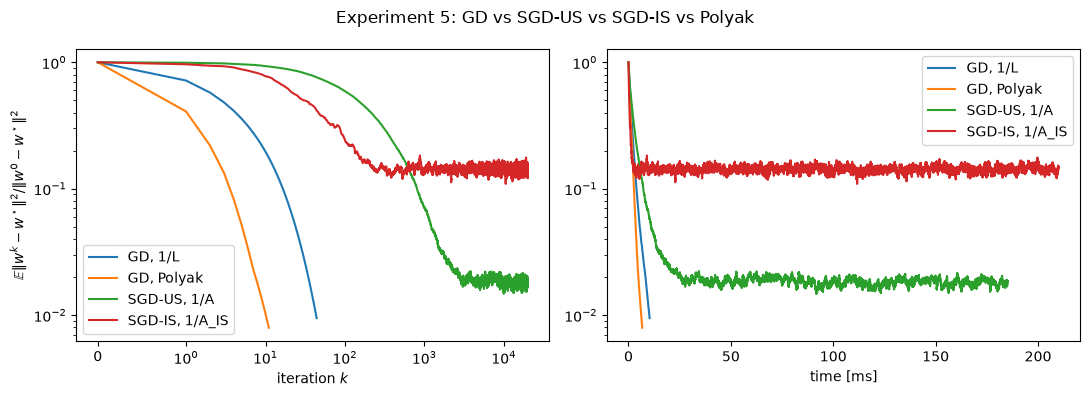

Steps, gradient evaluations and time until ||w^k - w*||^2 <= 0.01 ||w^0 - w*||^2:

method             |                                             | time / step
--------------------------------------------------------------------------------
GD, 1/L            |       44 steps,    726528 grads,    11.7 ms |    266.1 us
GD, Polyak         |       11 steps,    181632 grads,     8.9 ms |    806.3 us
SGD-US, 1/(4A)     |     8379 steps,      8379 grads,    84.9 ms |     10.1 us
SGD-US, 1/(2A)     |     4421 steps,      4421 grads,    44.4 ms |     10.0 us
SGD-US, 1/A        |     2680 steps,      2680 grads,    26.8 ms |     10.0 us
SGD-US, 2/A        |     2436 steps,      2436 grads,    24.4 ms |     10.0 us
SGD-US, 4/A        |    12331 steps,     12331 grads,   123.3 ms |     10.0 us
SGD-IS, 1/(4A_IS)  |     1816 steps,      1816 grads,    20.7 ms |     11.4 us
SGD-IS, 1/(2A_IS)  |     4767 steps,      4767 grads,    51.2 ms |     10.7 us
SGD-IS, 1/A_IS     |                 not reach

In [10]:
SGD_STEPS = 20000
RUNS4 = 50


def step_times(step, steps, seeds=SEEDS):
    # cumulative time of `steps` update steps (single runs), mean over seeds; t[0] = 0
    T = np.zeros((seeds, steps + 1))
    for s in range(seeds):
        rng = np.random.default_rng(SEED + 100 + s)
        w = W0.copy()
        for k in range(steps):
            t0 = time.perf_counter()
            w = step(w, rng)
            T[s, k + 1] = T[s, k] + time.perf_counter() - t0
    return T.mean(axis=0)


sgd_run = sgd(sgd_constant(1 / A), SGD_STEPS, runs=RUNS4)
t_sgd = step_times(sgd_step(1 / A), SGD_STEPS)
sgd_is_run = sgd(sgd_constant(1 / A_IS), SGD_STEPS, runs=RUNS4, p=p_is)
t_sgd_is = step_times(sgd_step(1 / A_IS, p_is), SGD_STEPS)
curves = {   # name -> (error at k = 0, 1, ..., time at each k)
    "GD, 1/L": (gd_const["err"], np.concatenate([[0.0], gd_const["time"]])),
    "GD, Polyak": (gd_pol["err"], np.concatenate([[0.0], gd_pol["time"]])),
    "SGD-US, 1/A": (sgd_run["err"], t_sgd),
    "SGD-IS, 1/A_IS": (sgd_is_run["err"], t_sgd_is),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, (err, t) in curves.items():
    axes[0].semilogy(np.arange(len(err)), err / R0, label=name)
    axes[1].semilogy(1e3 * t[:len(err)], err / R0, label=name)
axes[0].set_xscale("symlog", linthresh=1)
axes[0].set_xlabel("iteration $k$")
axes[1].set_xlabel("time [ms]")
axes[0].set_ylabel(r"$\mathbb{E}\|w^k-w^\star\|^2 / \|w^0-w^\star\|^2$")
for ax in axes:
    ax.legend()
fig.suptitle("Experiment 5: GD vs SGD-US vs SGD-IS vs Polyak")
save(fig, "log_exp5_comparison.png")

# SGD-IS rows of the table (measured here, not printed separately)
for label, gamma in [("1/(4A_IS)", 1 / (4 * A_IS)), ("1/(2A_IS)", 1 / (2 * A_IS)), ("1/A_IS", 1 / A_IS),
                     ("2/A_IS", 2 / A_IS)]:
    measure(f"SGD-IS, {label}", sgd_step(gamma, p_is), stochastic=True, max_steps=60000, verbose=False)

print(f"Steps, gradient evaluations and time until {TARGET}:\n")
print(f"{'method':18s} | {'':^43s} | {'time / step':>11s}")
print("-" * 80)
for name, res in RESULTS.items():
    per_step = f"{1e6 * res[2] / res[0]:8.1f} us" if res else ""
    print(f"{name:18s} | {fmt(res)} | {per_step:>11s}")